## Fitting and Covariance

When considering the uncertainty in fit parameters, it is important to recognize that the values of the parameters may not be independent of one another. For example, when fitting a linear equation to positive-valued points, an overestimate of the slope will tend to produce an underestimate of the y-intercept. This notebok shows an example of how to use the covariance matrix to visualize this uncertainty on a model.

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

The cell below generates some fake data that should follow a linear relationship, but with some scatter described by the random noise.

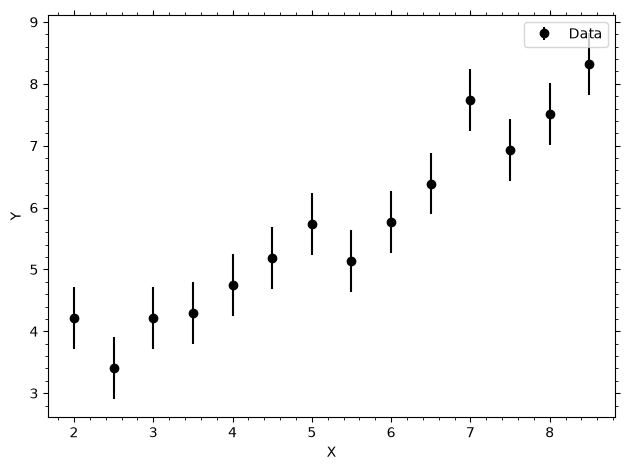

In [22]:
# define a linear function

def linfunc(x,c0,c1):
    return c0 + c1 * x

# generate fake X and Y data

rng = np.random.default_rng(seed=1216)

true_c0 = 2.7
true_c1 = 0.6
noise = 0.5

x_array = np.arange(2,9,0.5)
y_array = linfunc(x_array, true_c0, true_c1) + rng.normal(0,noise,len(x_array))

# plot fake data

fig,ax = plt.subplots()
ax.errorbar(x_array, y_array, noise, fmt = 'ko', label='Data')
ax.legend()
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.tick_params(which='both',axis='both',top=True, right=True)
ax.minorticks_on()
fig.tight_layout()

The cell below now fits a best-fit curve to that data, which produces a set of "optimal" parameters `popt`  (i.e., the best-fit y-intercept and slope) and their corresponding covariance matricx `pcov`.

We can use these to generate 100 random values of our y-intercept and slope that are consistent with the uncertainties. Notice that the values are **correlated**: higher values of the y-intercept are associated with negative values of the slope, and vice-versa:

popt = [2.07270402 0.68813688]
pcov = [[ 0.11863211 -0.01969387]
 [-0.01969387  0.00375121]]


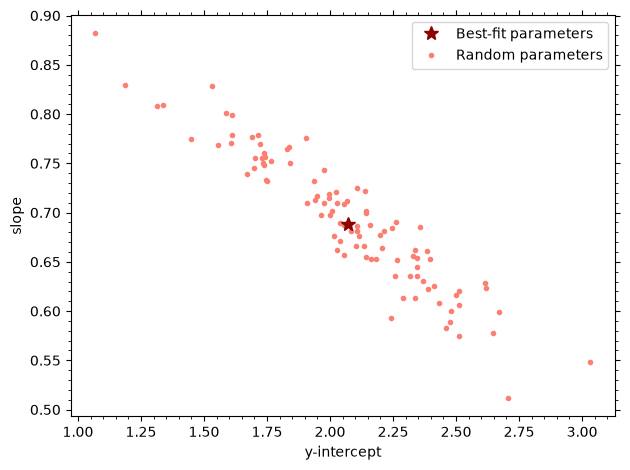

In [ ]:
# fit linear model to curve
popt, pcov = curve_fit(linfunc, x_array, y_array, sigma=noise)

# create 100 random versions of the parameters based on their covariance matrix
random_pars = rng.multivariate_normal(popt,pcov,size=100)

# plot random pairs of parameters according to fit uncertainties
fig, ax = plt.subplots()
ax.plot(popt[0],popt[1],'*',color='darkred',ms=10,label='Best-fit parameters',zorder=2)
ax.plot(random_pars[:,0],random_pars[:,1],'.',color='salmon',label='Random parameters',zorder=1)
ax.legend()
ax.set_xlabel('y-intercept')
ax.set_ylabel('slope')
ax.tick_params(which='both',axis='both',top=True, right=True)
ax.minorticks_on()
fig.tight_layout()


We can also see this from the fact that the off-diagonal elements of the covariance matrix `pcov` are negative. Note that the diagonal elements of `pcov` are related to the uncertainty in our slope and intercept, but the off-diagonal elements tell us about the correlation between them:

In [29]:
pcov


array([[ 0.11863211, -0.01969387],
       [-0.01969387,  0.00375121]])

One way to display the uncertainty on our fit model is to plot many versions of our fit based on each of the 100 random pairs of y-intercepts and slopes we generated above. If we plot 100 of these lines in addition to our best-fit line, they can help us visualize the other curves that are consistent with our uncertainties on the slope and y-intercept:

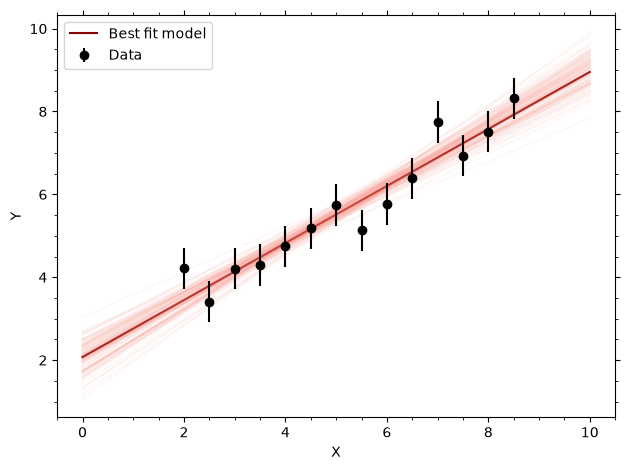

In [30]:
# plot best-fit model and 100 randomized versions based on covariance matrix

x_mod = np.linspace(0,10,100)
fig,ax = plt.subplots()
ax.errorbar(x_array, y_array, noise, fmt = 'ko', label='Data',zorder=2)
ax.plot(x_mod, linfunc(x_mod, *popt), '-', color='darkred',label='Best fit model',zorder=1)
for prand in random_pars:
       ax.plot(x_mod, linfunc(x_mod, *prand), '-', color='salmon',alpha=0.05,zorder=1)
ax.legend()
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.tick_params(which='both',axis='both',top=True, right=True)
ax.minorticks_on()
fig.tight_layout()


Putting all this together, we can also generate a function that produces a 1-sigma confidence interval around our fit model. This function assumes we have already fit our model to the data using `curve_fit`, such that we can include the following parameters as arguments:
- `x_mod`: the array of x-values at which we want to evaluate and display our model
- `func`: the function that we used with `curve_fit` to fit our model
- `popt`: the optimal parameters returned by `curve_fit`
- `pcov`: the parameter covariance matrix returned by `curve_fit`
- `ptile`: the percent probability interval that you want to display (e.g., use the default 68 for a 1-sigma interval, 95 for a 2-sigma interval)
- `nrand`: the number of random parameter pairs to generate from the covariance matrix. You shouldn't have to modify this, but you can increase the value for more precise intervals.

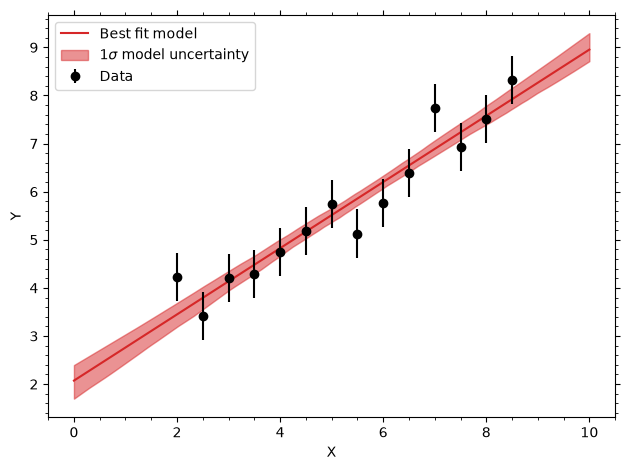

In [32]:
# generate and plot 1-sigma confidence interval on predicted curve

def gen_conf_interval(x_mod, func, popt, pcov, ptile = 68, nrand=100):
       rng = np.random.default_rng()
       random_pars = rng.multivariate_normal(popt,pcov,size=nrand)
       model_matrix = np.zeros((nrand,len(x_mod)))
       for i,prand in enumerate(random_pars):
              model_matrix[i] = func(x_mod, *prand)
       plo = 50 - ptile/2
       phi = 50 + ptile/2
       lower,upper = np.percentile(model_matrix,(plo,phi),axis=0)
       return lower,upper

lower, upper = gen_conf_interval(x_mod, linfunc, popt, pcov, nrand=100)

x_mod = np.linspace(0,10,100)
fig,ax = plt.subplots()
ax.errorbar(x_array, y_array, noise, fmt = 'ko', label='Data',zorder=2)
ax.plot(x_mod, linfunc(x_mod, *popt), '-', color='tab:red',label='Best fit model',zorder=1)
ax.fill_between(x_mod, lower, upper, color='tab:red', alpha=0.5, label='1$\\sigma$ model uncertainty',zorder=1)
ax.legend()
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.tick_params(which='both',axis='both',top=True, right=True)
ax.minorticks_on()
fig.tight_layout()


If you are already comfortable using `curve_fit`, you should be able to use the function above to generate confidence intervals on your fits. Note that you can copy and paste the function into other documents along with your existing curve-fitting code. See below for an example of applying it to a quadratic fit to the same data:


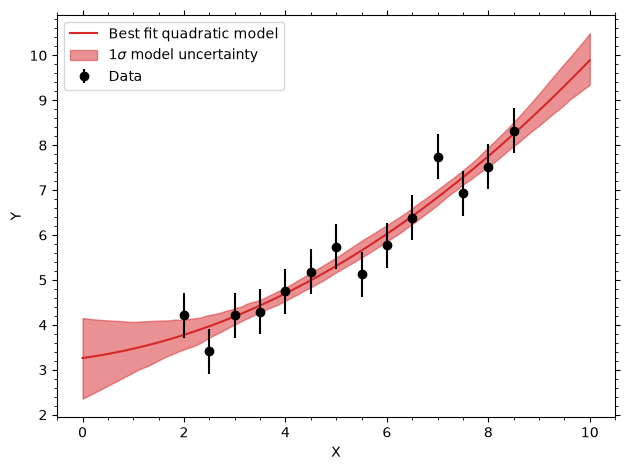

In [35]:
def quadfunc(x,c0,c1, c2):
    return c0 + c1 * x + c2 * x**2

popt_quad, pcov_quad = curve_fit(quadfunc, x_array, y_array, sigma=noise)

lower_quad, upper_quad = gen_conf_interval(x_mod, quadfunc, popt_quad, pcov_quad)

x_mod = np.linspace(0,10,100)
fig,ax = plt.subplots()
ax.errorbar(x_array, y_array, noise, fmt = 'ko', label='Data',zorder=2)
ax.plot(x_mod, quadfunc(x_mod, *popt_quad), '-', color='tab:red',label='Best fit quadratic model',zorder=1)
ax.fill_between(x_mod, lower_quad, upper_quad, color='tab:red', alpha=0.5, label='1$\\sigma$ model uncertainty',zorder=1)
ax.legend()
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.tick_params(which='both',axis='both',top=True, right=True)
ax.minorticks_on()
fig.tight_layout()


## Saving and submiting your notebook as a PDF

If you are in Google Colab, you can save your notebook as a PDF by following the steps below:
1. Make sure that all your cells have been run successfully and that you save your notebook for later reference.
2. Run the three cells below. *Note: the first cell may take **a few minutes** to run.*
3. Click the folder icon (&#x1F4C1;) on the left sidebar and look for the file called `my_notebook.pdf`. Hover your mouse over the file, click the three dots, and then download it to your computer. *You may wish to change the filename to something more descriptive, especially if you have other notebooks with the same name!*
4. Open the downloaded PDF and scroll through it to ensure that all of your work is visible. Once you are satisfied, submit the PDF to your instructor.

In [ ]:
%%capture

!apt-get install pandoc
!pip install nbconvert
!apt-get install texlive-xetex

In [ ]:
import json
from google.colab import _message

# Get the current notebook cells from the frontend
notebook_json = _message.blocking_request('get_ipynb', request='', timeout_sec=5)

# Save it as a file in the local Colab file browser
with open('my_notebook.ipynb', 'w') as f:
    json.dump(notebook_json['ipynb'], f)

print("Successfully saved 'my_notebook.ipynb' to the file browser panel.")


In [ ]:
!jupyter nbconvert --to pdf my_notebook.ipynb